# DASC8412 Assignment 2, Question 7: code generated by ChatGPT

**Student:** Cameron Totham (ST10301625)  
**Model:** ChatGPT (OpenAI, standard chat interface; model version not displayed)  
**Date generated:** 14 October 2026  
**Shared conversation:** https://chatgpt.com/share/6acf64ec-285c-83ea-adc7-66fbb7ddaf8f  
**Dataset:** School_Data_CSV.csv from Combrink, H., Carr, E., de Wet, K., Marivate, V. and Rosman, B. 2023. *South Africa Education Data and Visualisations*. University of the Free State. https://doi.org/10.38140/ufs.22081058.v4 (the CSV must be in the same folder as this notebook).

## Prompt (identical for both models; the CSV was attached)

> Attached above is a CSV file called School_Data_CSV.csv containing South African school data. Its contains columns such as, emisno, centername, institution_name, centreno, quintile, ward_id, street_address, new_long, new_lat.
>
> Write Python code that loads this file and creates the following three visualisations:
>
> a) A line plot showing how the number of schools per quintile changes across wards.
> b) A scatter plot showing the geographic locations of schools using new_lat and new_long.
> c) A histogram showing the distribution of schools by quintile.
>
> Provide the complete code.

## Note on the code

The code cells below are reproduced exactly as ChatGPT generated them. They have only been split into cells at the script's own section comments so that each chart appears under the code that produced it. ChatGPT did not run any code on the attached file; it returned this script directly.

In [1]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# --------------------------------------------------
# 1. LOAD AND PREPARE THE DATASET
# --------------------------------------------------

file_path = "School_Data_CSV.csv"

# Try common encodings to handle special characters
for encoding in ["utf-8", "cp1252", "latin1"]:
    try:
        df = pd.read_csv(file_path, encoding=encoding)
        break
    except UnicodeDecodeError:
        continue

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Check that the required columns exist
required_columns = [
    "quintile", "ward_id", "new_lat", "new_long"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert relevant columns to appropriate types
df["quintile"] = pd.to_numeric(
    df["quintile"], errors="coerce"
)
df["new_lat"] = pd.to_numeric(
    df["new_lat"], errors="coerce"
)
df["new_long"] = pd.to_numeric(
    df["new_long"], errors="coerce"
)

# Remove records without a quintile or ward
df = df.dropna(subset=["quintile", "ward_id"])

# Keep only valid South African school quintiles (1 to 5)
df = df[df["quintile"].between(1, 5)]
df["quintile"] = df["quintile"].astype(int)

# Set a consistent visual style
sns.set_theme(style="whitegrid")

~\AppData\Local\Temp\ipykernel_28356\2228546609.py:10: DtypeWarning: Columns (0: emisno, 1: new_long) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, encoding=encoding)


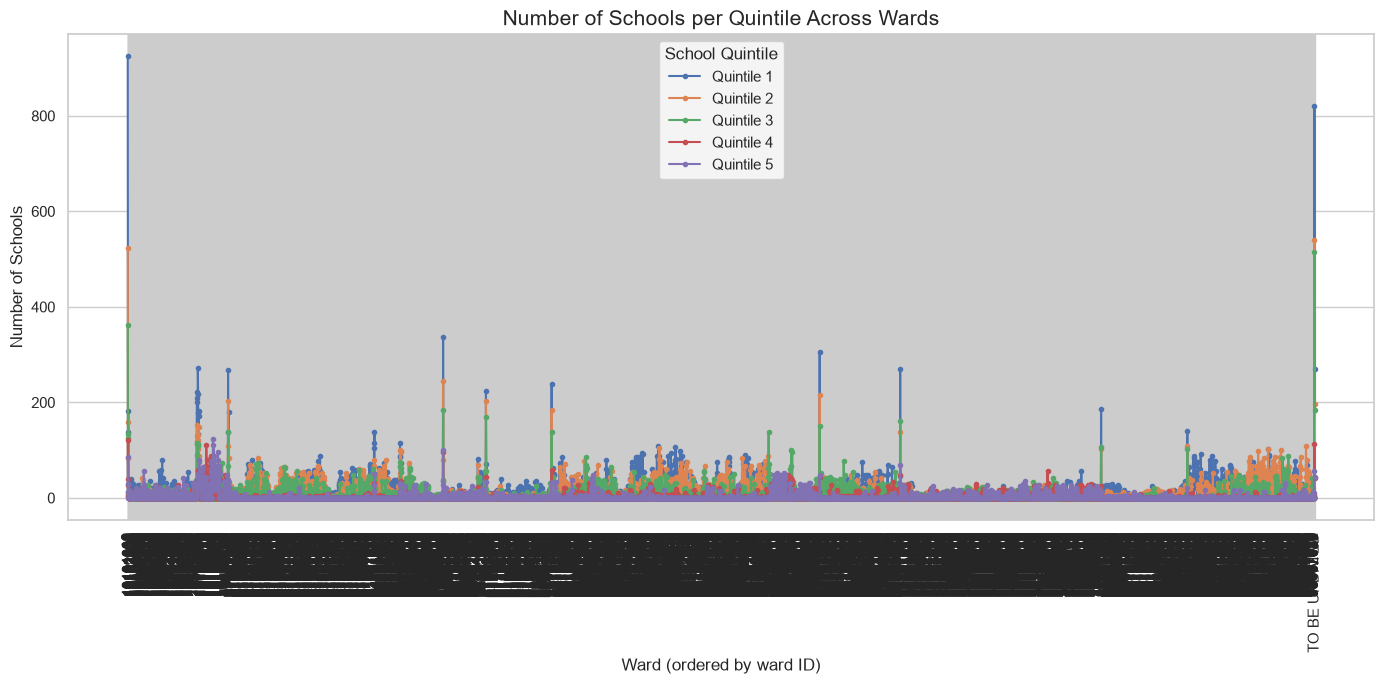

In [3]:
# --------------------------------------------------
# A) LINE PLOT: SCHOOLS PER QUINTILE ACROSS WARDS
# --------------------------------------------------

# Count schools in each ward and quintile
ward_quintile_counts = (
    df.groupby(["ward_id", "quintile"])
      .size()
      .reset_index(name="number_of_schools")
)

# Convert quintiles into separate columns
line_data = ward_quintile_counts.pivot(
    index="ward_id",
    columns="quintile",
    values="number_of_schools"
).fillna(0)

# Sort wards by their identifier
line_data = line_data.sort_index()

# Plot one line for each quintile
plt.figure(figsize=(14, 7))

for quintile in sorted(line_data.columns):
    plt.plot(
        range(len(line_data)),
        line_data[quintile],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=f"Quintile {quintile}"
    )

plt.title(
    "Number of Schools per Quintile Across Wards",
    fontsize=15
)
plt.xlabel("Ward (ordered by ward ID)")
plt.ylabel("Number of Schools")
plt.xticks(
    range(len(line_data)),
    line_data.index.astype(str),
    rotation=90
)
plt.legend(title="School Quintile")
plt.tight_layout()
plt.show()

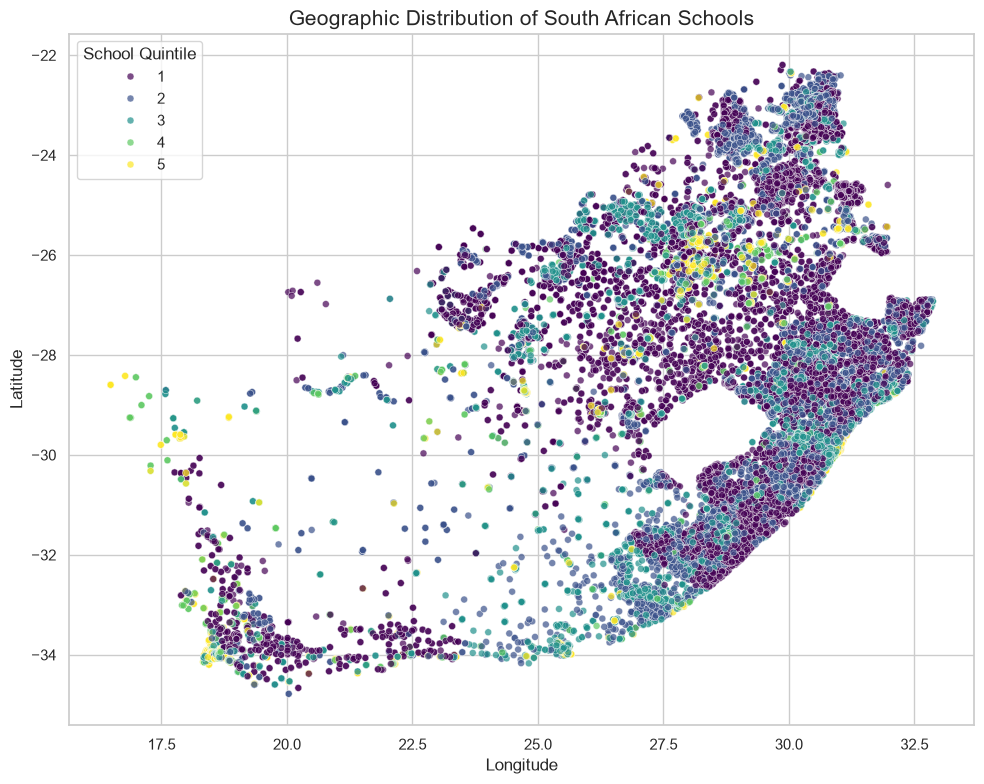

In [4]:
# --------------------------------------------------
# B) SCATTER PLOT: GEOGRAPHIC LOCATIONS OF SCHOOLS
# --------------------------------------------------

# Keep records with valid geographic coordinates
geo_data = df.dropna(subset=["new_lat", "new_long"])

# Remove coordinates outside South Africa's approximate bounds
geo_data = geo_data[
    geo_data["new_lat"].between(-35, -22)
    & geo_data["new_long"].between(16, 33)
]

plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=geo_data,
    x="new_long",
    y="new_lat",
    hue="quintile",
    palette="viridis",
    hue_order=[1, 2, 3, 4, 5],
    alpha=0.7,
    s=25
)

plt.title(
    "Geographic Distribution of South African Schools",
    fontsize=15
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="School Quintile")
plt.tight_layout()
plt.show()

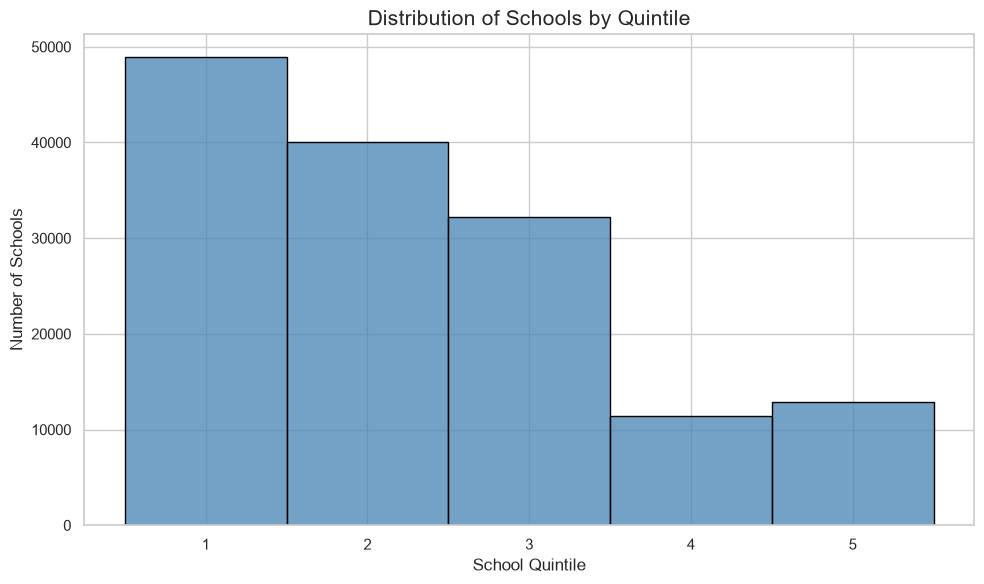

In [5]:
# --------------------------------------------------
# C) HISTOGRAM: DISTRIBUTION OF SCHOOLS BY QUINTILE
# --------------------------------------------------

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="quintile",
    bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
    color="steelblue",
    edgecolor="black"
)

plt.title(
    "Distribution of Schools by Quintile",
    fontsize=15
)
plt.xlabel("School Quintile")
plt.ylabel("Number of Schools")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()